<font color="#0D9DF0"><h3><b>ANÁLISE DO DESENVOLVIMENTO TURÍSCO BRASILEIRO</b></h3></font>

**Base de dados:** IBGE,Ipeadata

**Grupo:** Leandro Mendes, Thiago Patente, André e Gabriel Moreira. 

#### Objetivo do trabalho
**Pergunta central:** Variação do volume de viagens nacionais conforme evolução do PIB per capita?
Para investigar essa pergunta, utilizamos um indicador de viagens por
motivo pessoal,pib per capita e taxa de inflação.
A análise é descritiva e exploratória: não identifica causalidade.

**Etapas do notebook**
1. Coleta e exploração inicial
2. Limpeza e preparação
3. Análise exploratória
4. Funções de visualização
5. Interpretação das análises
6. Síntese e conclusão

#### Importação das bibliotecas

In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

INICIO = Path.cwd().resolve()

# Procura a raiz do projeto na pasta inicial e nas pastas superiores.
PROJETO = next(
    (pasta for pasta in [INICIO, *INICIO.parents]
     if (pasta / "util").is_dir() and (pasta / "dados").is_dir()),
    None,
)
if PROJETO is None:
    raise FileNotFoundError("Não encontrei a raiz do projeto.")

if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

from util import (
    # Reaproveitadas da pergunta 1
    ler_tabela_sidra_horizontal,
    resumo_duplicados,
    remover_duplicados,
    resumo_ausentes,
    verificar_cobertura,
    filtrar_anos,
    grafico_total_por_ano,
    salvar_figura,
    # Novas — pergunta 2
    ler_titulo_ipeadata,
    identificar_arquivo_ipeadata,
    ler_ipeadata_por_uf,
    ler_ipeadata_serie_anual,
    juntar_indicador,
    variacao_indicador,
    tabela_contingencia_indicador,
    teste_robustez_indicador,
    resumo_choque_indicador,
    grafico_dispersao_indicador,
    grafico_indices_duplos,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

ARQ_TURISMO = PROJETO / "dados" / "Tabela 7266.xlsx"
ARQUIVOS_IPEA = sorted((PROJETO / "dados").glob("ipeadata*.csv"))

SAIDA = PROJETO / "dados" / "saida" / "pergunta2"
SAIDA.mkdir(parents=True, exist_ok=True)

ANOS_PANDEMIA = [2020, 2021]
PAR_PRINCIPAL = (2019, 2023)
PAR_RECUPERACAO = (2021, 2023)
PAR_CHOQUE = (2019, 2020)

# Mesmos cenários de sensibilidade da pergunta 1.
CENARIOS = {
    "Todas as UFs": [],
    "Sem Roraima": ["RR"],
    "Sem Roraima e Amapá": ["RR", "AP"],
}

CHAVES = ["cod_ibge", "ano"]


---

## 1. Coleta de Dados
**Etapa atual:  COLETA**

Carregamos a Tabela 7266 da PNAD Contínua (viagens por UF de destino) e dois arquivos do Ipeadata.
Os arquivos do Ipeadata têm nomes genéricos; por isso, **identificamos cada um pelo título
da primeira linha**,  e não pelo nome do arquivo.

Isso ocorre devido os arquivos exportados da base de ipeadata não terem diferenciação pelo nome do arquivo logo precisa analisa o título para descobri se o arquivo é do pib per capita por estado ou se é a taxa de inflação.

In [3]:
identificados = {}

for arq in ARQUIVOS_IPEA:
    tipo = identificar_arquivo_ipeadata(arq)
    print(f"{arq.name} → {tipo}")
    print(f"   Título: {ler_titulo_ipeadata(arq)}\n")

    if tipo == "desconhecido":
        continue
    if tipo in identificados:
        raise ValueError(f"Mais de um arquivo identificado como '{tipo}'.")
    identificados[tipo] = arq

ARQ_PIB = identificados["pib_per_capita"]
ARQ_INFLACAO = identificados["inflacao"]

ipeadata[02-11-2026-07-17].csv → pib_per_capita
   Título: PIB Estadual per capita - preços de mercado (preços de 2010)

ipeadata[02-11-2026-07-21].csv → inflacao
   Título: Data;IPC (FIPE) - taxa de inflação - (% a.a.) - Fundação Instituto de Pesquisas Econômicas (Fipe) - FIPE_FIPE0001



In [4]:
turismo_bruto = ler_tabela_sidra_horizontal(
    ARQ_TURISMO,
    aba="Tabela",
    nome_valor="viagens_mil",
)

pib_bruto = ler_ipeadata_por_uf(ARQ_PIB, nome_valor="pib_pc_mil")
inflacao = ler_ipeadata_serie_anual(ARQ_INFLACAO, nome_valor="ipc_fipe_pct")

In [11]:
print("Arquivo de viagens:", ARQ_TURISMO)
print("Arquivo de homicídios:", ARQ_HOMICIDIOS)

Arquivo de viagens: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\Tabela 7266.xlsx
Arquivo de homicídios: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\Taxa de homicídios registrados_estados.csv


## 2. Exploração Inicial dos Dados
**Etapa atual:  EXPLORAÇÃO INICIAL**


Verificamos a estrutura, os tipos, a quantidade de registros, os anos disponíveis e as estatísticas descritivas.

In [5]:
print("Informações das viagens:")
turismo_bruto.info()

print("\nInformações do PIB per capita:")
pib_bruto.info()

print("\nPrimeiras linhas do PIB per capita:")
print(pib_bruto.head())

print("\nEstatísticas do PIB per capita (R$ mil de 2010) por ano:")
print(pib_bruto.groupby("ano")["pib_pc_mil"].describe().round(2))

print("\nAnos — viagens:", sorted(turismo_bruto["ano"].unique()))
print("Anos — PIB per capita:", sorted(pib_bruto["ano"].unique()))

print("\nInflação IPC-FIPE (% a.a.) — apenas contexto:")
print(inflacao.query("2019 <= ano <= 2024").round(2).to_string(index=False))

Informações das viagens:
<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   cod_ibge     135 non-null    int64  
 1   uf           135 non-null    str    
 2   estado       135 non-null    str    
 3   ano          135 non-null    int64  
 4   viagens_mil  135 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 5.4 KB

Informações do PIB per capita:
<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   uf          135 non-null    str    
 1   cod_ibge    135 non-null    int64  
 2   estado      135 non-null    str    
 3   ano         135 non-null    int64  
 4   pib_pc_mil  135 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 5.4 KB

Primeiras linhas do PIB per capita:
   uf  cod_ibge    esta

**Analise do resultado**
- O arquivo `ipeadata[02-11-2026-07-17].csv` é o **PIB Estadual per capita — preços de mercado (preços de 2010)**.
  Ele já tem as colunas Sigla, Código (IBGE) e Estado e cobre de 2019 a 2023.
- O arquivo `ipeadata[02-11-2026-07-21].csv` é a **taxa de inflação do IPC-FIPE (% a.a.)**, de 1940 a 2025.
- Como o PIB per capita já está **a preços de 2010**, ou seja, já descontada a inflação, **não o corrigimos de novo**.
  Uma nova correção descontaria a inflação duas vezes.
- O IPC-FIPE mede os preços ao consumidor do município de São Paulo. Por isso, é usado apenas como contexto.
- Anos em comum entre viagens e PIB: **2019, 2020, 2021 e 2023**. Faltam 2022 nas viagens e 2024 no PIB.

## 3. Limpeza de Dados
**Etapa atual:  TRATAMENTO**

Verificamos registros duplicados e dados ausentes nas duas bases.
Não imputamos valores: médias artificiais poderiam alterar as variações e as associações investigadas.

In [9]:

print("Diagnóstico de duplicados:")
for nome, df in {"Viagens": turismo_bruto, "PIB per capita": pib_bruto}.items():
    duplicados = resumo_duplicados(df, CHAVES)
    print(f"\n{nome}: {len(duplicados)} linhas com chaves repetidas")
    if len(duplicados):
        print(duplicados)

print("\nDiagnóstico de ausentes — viagens:")
print(resumo_ausentes(turismo_bruto))

print("\nDiagnóstico de ausentes — PIB per capita:")
print(resumo_ausentes(pib_bruto))


Diagnóstico de duplicados:

Viagens: 0 linhas com chaves repetidas

PIB per capita: 0 linhas com chaves repetidas

Diagnóstico de ausentes — viagens:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Diagnóstico de ausentes — PIB per capita:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []


In [8]:
turismo_sem_identicos = turismo_bruto.drop_duplicates()
pib_sem_identicos = pib_bruto.drop_duplicates()

for nome, df in {"Viagens": turismo_sem_identicos,
                 "PIB per capita": pib_sem_identicos}.items():
    conflitos = resumo_duplicados(df, CHAVES)
    if len(conflitos):
        print(conflitos)
        raise ValueError(f"{nome}: conferir registros conflitantes por UF e ano.")

turismo_limpo = remover_duplicados(turismo_sem_identicos, CHAVES)
pib_limpo = remover_duplicados(pib_sem_identicos, CHAVES)

turismo_limpo = turismo_limpo.dropna(
    subset=CHAVES + ["uf", "estado", "viagens_mil"]
).copy()
pib_limpo = pib_limpo.dropna(subset=CHAVES + ["uf", "pib_pc_mil"]).copy()

auditoria = pd.DataFrame([
    {"base": "Viagens", "linhas_antes": len(turismo_bruto),
     "linhas_depois": len(turismo_limpo)},
    {"base": "PIB per capita", "linhas_antes": len(pib_bruto),
     "linhas_depois": len(pib_limpo)},
])
auditoria["linhas_removidas"] = auditoria["linhas_antes"] - auditoria["linhas_depois"]
print(auditoria)

             base  linhas_antes  linhas_depois  linhas_removidas
0         Viagens           135            135                 0
1  PIB per capita           135            135                 0


**Decisões de tratamento**
 
- Se aparecer uma ausência no futuro, ela não será preenchida com médias ou interpolações.
  Também será preciso verificar se ela compromete a cobertura por UF e ano.


- A primeira linha (título) foi ignorada na leitura e usada apenas para identificar o arquivo.
- Removemos a coluna vazia `Unnamed`, criada pelo `;` no fim de cada linha.
- Removemos o caractere invisível (BOM) do início do arquivo.
- Convertemos a vírgula decimal para o padrão numérico do Python.
- Passamos a tabela do formato largo (um ano por coluna) para o formato longo (uma linha por UF e ano).

- Os valores já estão a preços de 2010.
  Corrigi-los de novo descontaria a inflação duas vezes .

- A série mede a inflação do município de São Paulo e não foi
  usada para deflacionar o PIB. Por ser uma série nacional, sem UF, ela não entra na junção.

- Faltam 2022 nas viagens e 2024 no PIB.
  Esses anos não foram estimados nem interpolados; a seleção dos anos em comum é feita na etapa 4.

- RR e AP aparecem só nos cenários de sensibilidade.

## 4. Transformação e Preparação dos Dados

- Selecionar os anos disponíveis nas duas fontes.
- Padronizar os tipos numéricos e conferir a cobertura.
- Integrar por código IBGE e ano, sem usar a posição das linhas.
- Conferir se a sigla da UF coincide nas duas bases.
- Calcular as variações entre os pares de anos analisados.

In [11]:
ANOS_ANALISE = sorted(set(turismo_limpo["ano"]) & set(pib_limpo["ano"]))
print("Anos em comum:", ANOS_ANALISE)

if ANOS_ANALISE != [2019, 2020, 2021, 2023]:
    raise ValueError("Anos em comum diferentes do esperado; revisar as fontes.")

turismo = filtrar_anos(turismo_limpo, ANOS_ANALISE).copy()
pib = filtrar_anos(pib_limpo, ANOS_ANALISE).copy()

for df in [turismo, pib]:
    df["cod_ibge"] = pd.to_numeric(df["cod_ibge"], errors="raise").astype(int)
    df["ano"] = pd.to_numeric(df["ano"], errors="raise").astype(int)

if turismo["viagens_mil"].lt(0).any() or pib["pib_pc_mil"].le(0).any():
    raise ValueError("Valores inválidos (negativos ou zero) encontrados.")

print("Cobertura — viagens:")
print(verificar_cobertura(turismo))
print("\nCobertura — PIB per capita:")
print(verificar_cobertura(pib))

base = juntar_indicador(turismo, pib, "pib_pc_mil")

if len(base) != 27 * len(ANOS_ANALISE):
    raise ValueError("Quantidade inesperada de registros após a junção.")
if base.duplicated(CHAVES).any():
    raise ValueError("A junção produziu chaves duplicadas.")
if base[["viagens_mil", "pib_pc_mil"]].isna().any().any():
    raise ValueError("A base integrada contém valores ausentes.")

print(base.head(10))

# Resumo anual: soma das viagens e MEDIANA do PIB per capita
# (valores per capita não podem ser somados entre UFs).
resumo_anual = base.groupby("ano").agg(
    viagens_mil=("viagens_mil", "sum"),
    pib_pc_mediana=("pib_pc_mil", "median"),
)
resumo_anual["viagens_vs_2019_pct"] = (
    (resumo_anual["viagens_mil"] / resumo_anual.loc[2019, "viagens_mil"] - 1) * 100
).round(1)
resumo_anual["pib_mediana_vs_2019_pct"] = (
    (resumo_anual["pib_pc_mediana"] / resumo_anual.loc[2019, "pib_pc_mediana"] - 1) * 100
).round(1)

var_principal = variacao_indicador(base, *PAR_PRINCIPAL, "pib_pc_mil", "pib")
var_recuperacao = variacao_indicador(base, *PAR_RECUPERACAO, "pib_pc_mil", "pib")
var_choque = variacao_indicador(base, *PAR_CHOQUE, "pib_pc_mil", "pib")

print(resumo_anual.round(2))

Anos em comum: [2019, 2020, 2021, 2023]
Cobertura — viagens:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True

Cobertura — PIB per capita:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True
   cod_ibge  uf     estado   ano  viagens_mil  pib_pc_mil
0        11  RO   Rondônia  2019         93.0   14.887911
1        12  AC       Acre  2019         40.0    9.957677
2        13  AM   Amazonas  2019        162.0   14.665748
3        14  RR    Roraima  2019         25.0   13.256649
4        15  PA       Pará  2019        773.0   11.671955
5        16  AP      Amapá  2019         45.0   11.624067
6        17  TO  Tocantins  2019        175.0   14.058978
7        21  MA   Maranhão  2019        439.0    7.730163
8        22  PI      Piauí  2019        508.0    9.083923
9        23  CE      Ceará  2019        748.0   10.064295
      viagens_mil  pib_pc_median


**Atenção às unidades:** valores de PIB per capita estaduais não podem ser somados.
Para obter um PIB per capita nacional, seriam necessários o PIB e a população de cada UF.
Por isso, para o resumo anual deve-se usa a mediana entre as UFs.

## 5. Análise exploratória dos dados

### 5.1. Viagens × PIB per capita
Comparação principal: **2019 → 2023** (antes e depois da pandemia).
Cautela: em 2019, a fonte usa só o 3º trimestre; a partir de 2020, usa o acumulado de segundas visitas.

**Pergunta 1** — O aumento do PIB per capita foi acompanhado de aumento das viagens?


In [12]:
contingencia_principal = tabela_contingencia_indicador(var_principal, "pib")
print(contingencia_principal)

viagens_mov  caiu  subiu  Total
pib_mov                        
subiu          17     10     27
Total          17     10     27


## Analisando o resultado de cima pode-se afirmar que:

O PIB per capita real subiu nas 27 UFs entre 2019 e 2023, por isso a tabela tem uma única linha para cada estado.
Mesmo assim, mostra que as viagens recuaram em 17 UFs e aumentaram em 10.
Como não há UFs com queda do PIB, a tabela não separa grupos(subiram e desceram) a associação será avaliada pela
intensidade das variações (correlação e dispersão).

**Pergunta 2** — As variações apresentam associação?

Os cenários sem RR e AP avaliam a sensibilidade do resultado. Eles não justificam excluir essas UFs do resultado principal.


In [13]:
robustez = teste_robustez_indicador(var_principal, "pib", CENARIOS)
print(robustez)


               cenario   n  pearson  p_pearson  spearman  p_spearman  inclinacao  r_critico_5pct  significativo_5pct
0         Todas as UFs  27   -0.389      0.045    -0.297       0.132      -0.902           0.381                True
1          Sem Roraima  26   -0.387      0.051    -0.257       0.205      -0.846           0.388               False
2  Sem Roraima e Amapá  25   -0.303      0.141    -0.177       0.398      -0.694           0.396               False


Ao o que tudo indica as correlações estão bem abaixa de 1 o que indica que não há quase nenhuma correlação.
Não significa que a pib crescimento do pib per capita acompanhou o crescimento das viagens ou sua diminuição.

**Pergunta 3** — O que acontece na fase de recuperação (2021 → 2023)?

Esta comparação é complementar, não uma confirmação independente.

Ela envolve o período da pandemia e diferenças na apresentação metodológica da fonte de viagens.

In [15]:
contingencia_recuperacao = tabela_contingencia_indicador(var_recuperacao, "pib")
robustez_recuperacao = teste_robustez_indicador(var_recuperacao, "pib", CENARIOS)
print(contingencia_recuperacao)
print(robustez_recuperacao)

viagens_mov  subiu  Total
pib_mov                  
caiu             3      3
subiu           24     24
Total           27     27
               cenario   n  pearson  p_pearson  spearman  p_spearman  inclinacao  r_critico_5pct  significativo_5pct
0         Todas as UFs  27    0.621      0.001     0.203       0.309       3.497           0.381                True
1          Sem Roraima  26    0.632      0.001     0.200       0.327       3.596           0.388                True
2  Sem Roraima e Amapá  25    0.134      0.522     0.100       0.634       0.329           0.396               False


Entre 2021 e 2023, as viagens recebidas aumentaram nas 27 UFs, e o PIB per capita real aumentou em 24
(caiu em três). Como todas as UFs tiveram aumento das viagens, a tabela de contingência não separa grupos.

A correlação de Pearson com todas as UFs foi positiva e relevante  porem fraca igualmente com a correlação de sperman.

Portanto, o resultado depende de um número pequeno de UFs com variações extremas, em especial o Amapá,
e não é confirmado pela correlação por postos. Nessa fase predomina a retomada pós-pandemia,
comum a todo o país. Não há evidência consistente de associação entre o PIB per capita e a variação
das viagens, e o resultado não permite inferir causalidade.

### 5.2. Análise dos anos da pandemia e sua exclusão da análise principal

**Pergunta 4** — Como evoluíram as viagens e o PIB per capita em relação a 2019?


In [16]:
print(resumo_anual.round(2))


      viagens_mil  pib_pc_mediana  viagens_vs_2019_pct  pib_mediana_vs_2019_pct
ano                                                                            
2019      17066.0           14.06                  0.0                      0.0
2020      11162.0           14.48                -34.6                      3.0
2021      10274.0           14.38                -39.8                      2.3
2023      17171.0           16.62                  0.6                     18.2


O resultado demonstra que os anos de 2020 e 2021 tiveram uma variação enorme na taxa de viagens, isso indica o impacto da pandemia e o por quê da decisão de exclusão dos dados de 2020 e 2021 na analises.

**Pergunta 5** — No choque de 2020, o PIB per capita e as viagens caíram juntos?


In [17]:
print(resumo_choque_indicador(var_choque, "pib", "PIB per capita"))


UFs analisadas                                                            27
PIB per capita caiu                                                       19
Viagens caíram                                                            27
Ambos caíram                                                              19
UFs com ambas as quedas    [AC, AM, AP, PI, CE, RN, PB, PE, SE, BA, MG, E...
dtype: object


A pandemia teve novamente um impacto massivo tanto nas vigens(mostrada da parte 1) quanto agora no pib per capita.

**Pergunta 6** — Quais UFs tiveram as maiores e as menores variações do PIB per capita (2019 → 2023)?


In [18]:
colunas = ["uf", "pib_var_pct", "viagens_var_pct"]
print("Maiores variações do PIB per capita:")
print(var_principal.nlargest(5, "pib_var_pct")[colunas].round(1))
print("\nMenores variações do PIB per capita:")
print(var_principal.nsmallest(5, "pib_var_pct")[colunas].round(1))

Maiores variações do PIB per capita:
    uf  pib_var_pct  viagens_var_pct
5   AP         33.6            -40.0
0   RO         32.3            -10.8
24  MT         31.1            -33.8
1   AC         29.5            -47.5
23  MS         25.0            -17.0

Menores variações do PIB per capita:
    uf  pib_var_pct  viagens_var_pct
22  RS          2.5              2.2
14  SE          2.6            -22.3
26  DF          3.5            -13.6
20  PR          4.0              3.4
11  PB          4.4              6.2


Os maiores aumentos ocorreram no Amapá (33,6%), em Rondônia (32,3%), no Mato Grosso (31,1%), no Acre (29,5%) e no Mato Grosso do Sul (25,0%).
Os menores aumentos foram os do Rio Grande do Sul (2,5%), de Sergipe (2,6%), do Distrito Federal (3,5%),
do Paraná (4,0%) e da Paraíba (4,4%).

As cinco UFs com maior crescimento do PIB tiveram queda nas viagens recebidas (de −10,8% a −47,5%).
Entre as cinco com menor crescimento, três tiveram aumento nas viagens (RS, PR e PB). O padrão é coerente com a
correlação negativa e frágil encontrada anteriormente, mas descreve apenas os extremos. Além disso, AP, AC e RO têm base
pequena de viagens, o que torna as variações percentuais mais instáveis e volateis demais . Trata-se de associação descritiva, sem
interpretação causal.

## 6. Funções de visualização gráfica



Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta2\total_viagens_por_ano.png


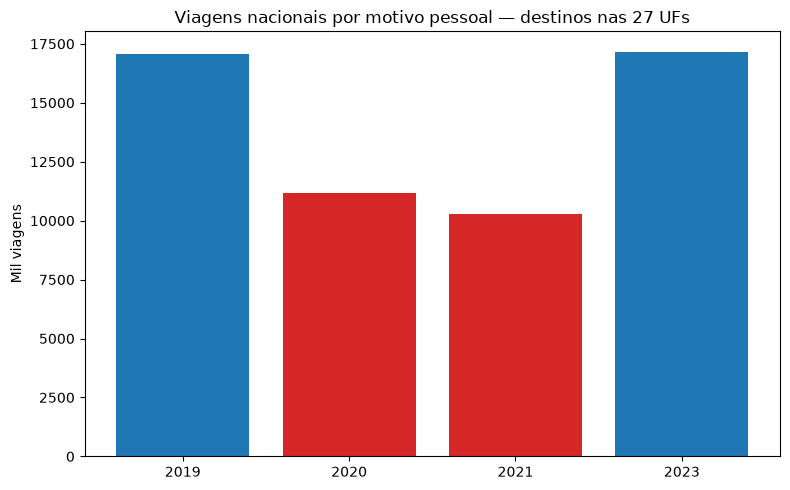

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta2\dispersao_pib_2019_2023.png


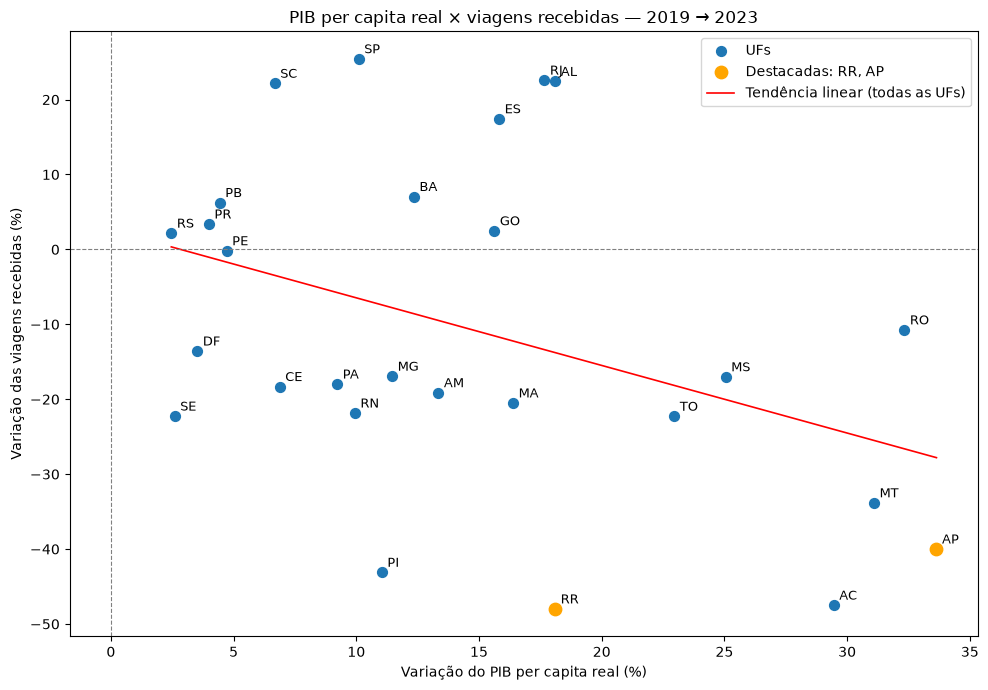

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta2\dispersao_pib_2021_2023.png


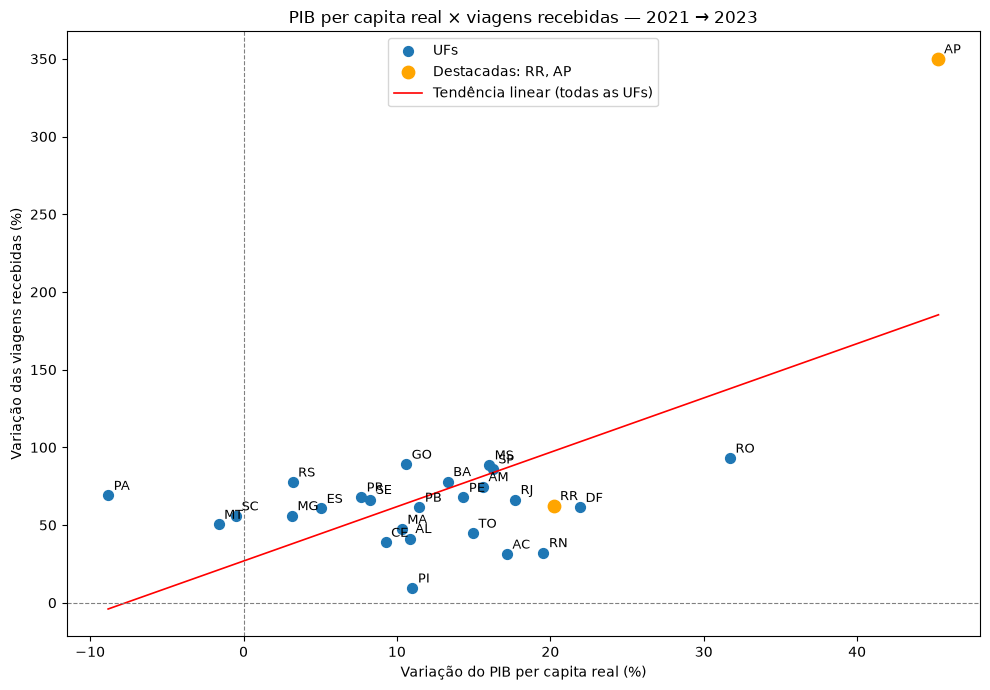

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta2\indices_pib_viagens_ufs.png


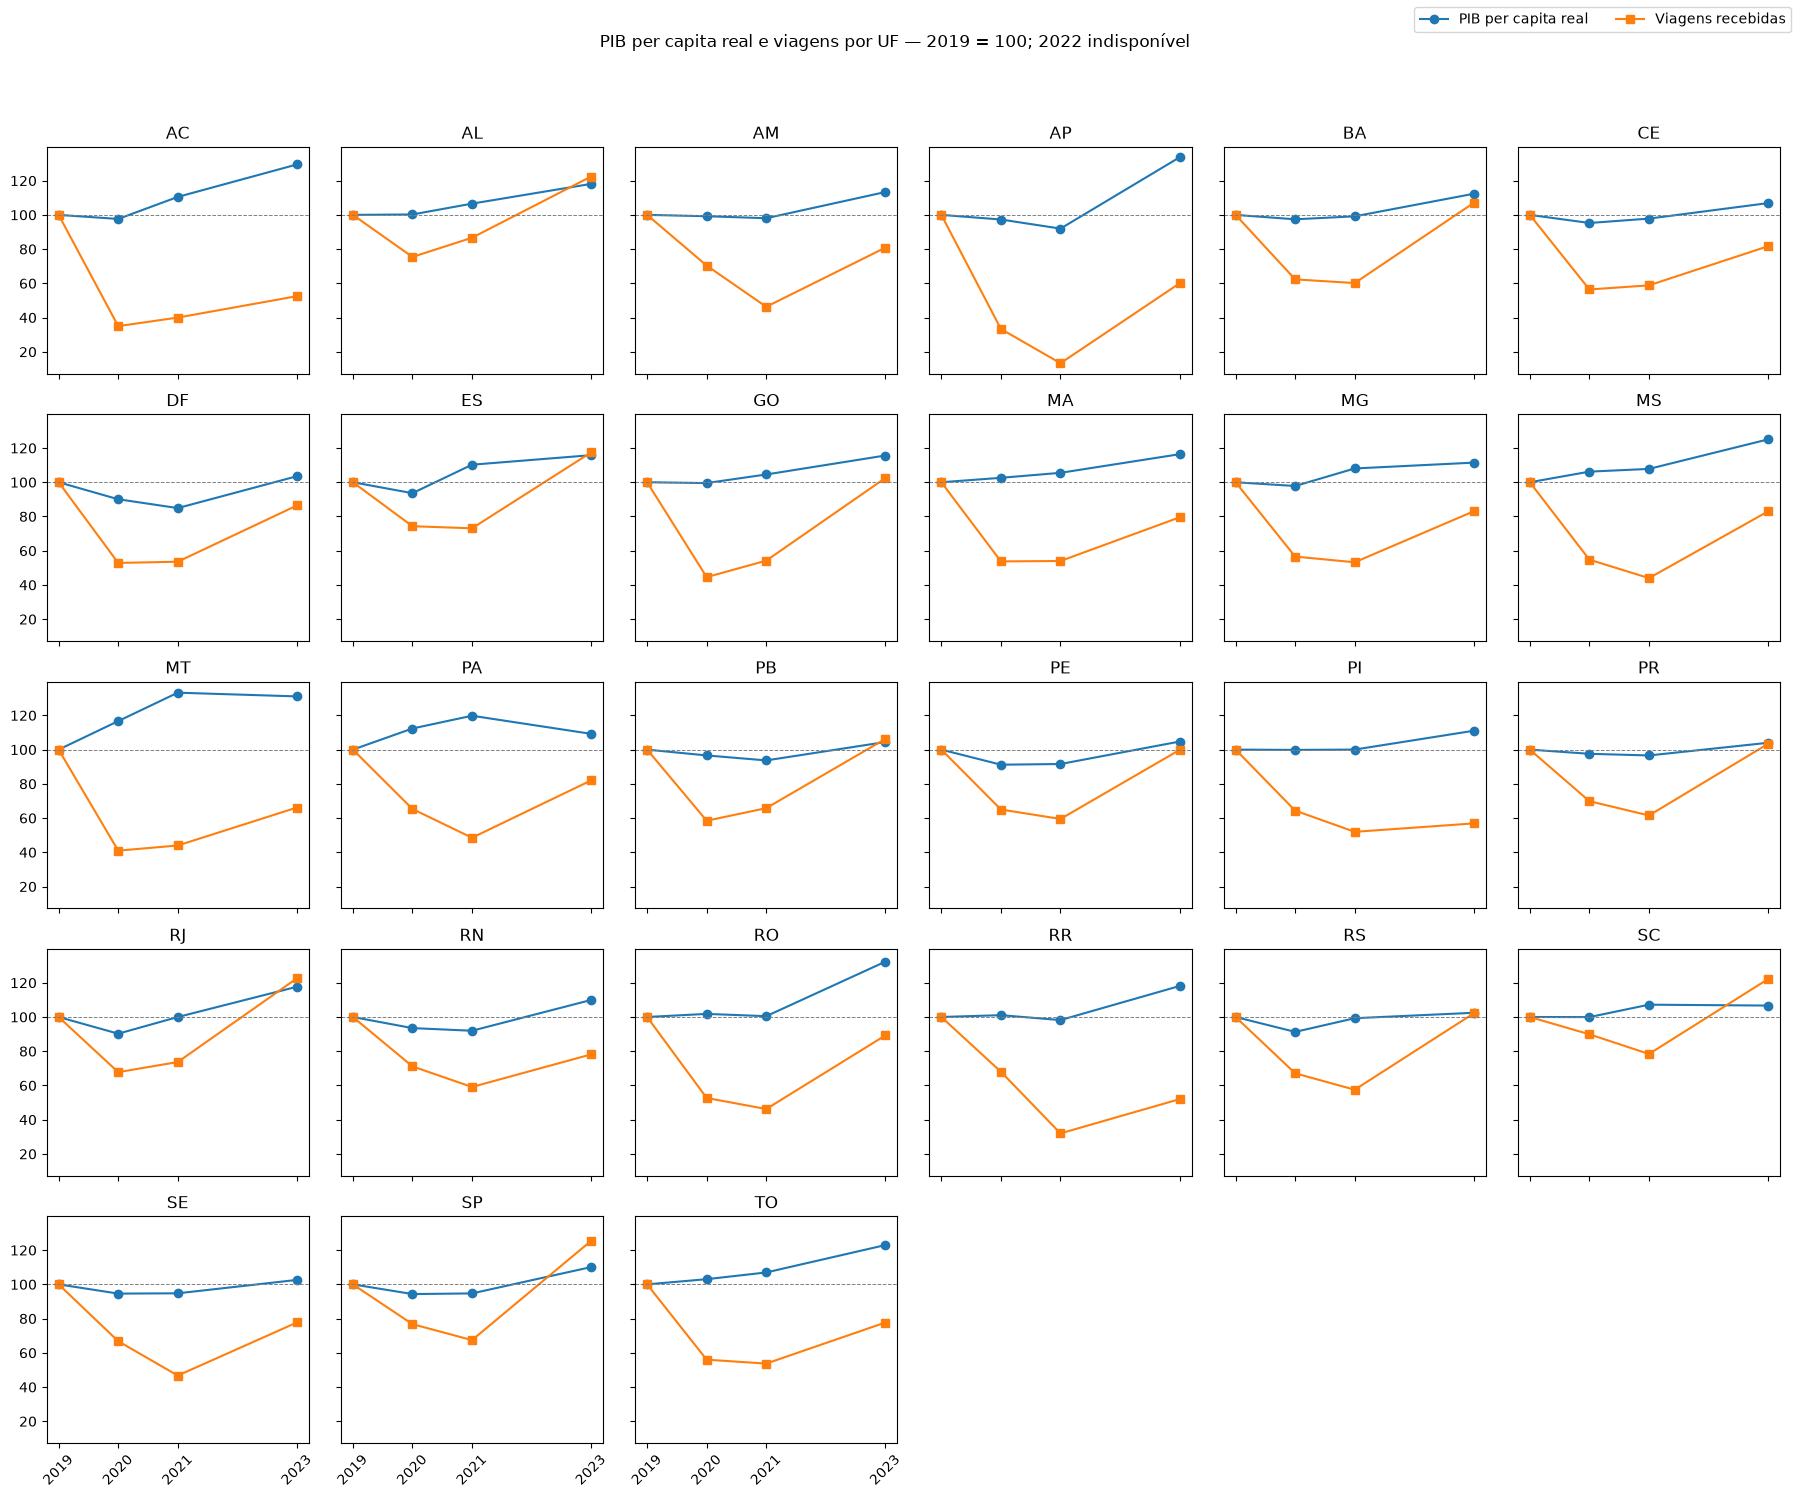

In [19]:
fig_total = grafico_total_por_ano(
    base,
    "viagens_mil",
    destaque=ANOS_PANDEMIA,
    titulo="Viagens nacionais por motivo pessoal — destinos nas 27 UFs",
    rotulo_y="Mil viagens",
)
salvar_figura(fig_total, str(SAIDA / "total_viagens_por_ano.png"))
plt.show()
plt.close(fig_total)

for (ini, fim), var in {PAR_PRINCIPAL: var_principal,
                        PAR_RECUPERACAO: var_recuperacao}.items():
    fig = grafico_dispersao_indicador(
        var,
        "pib",
        f"PIB per capita real × viagens recebidas — {ini} → {fim}",
        "Variação do PIB per capita real (%)",
        destacar=("RR", "AP"),
    )
    salvar_figura(fig, str(SAIDA / f"dispersao_pib_{ini}_{fim}.png"))
    plt.show()
    plt.close(fig)

fig_ind = grafico_indices_duplos(
    base,
    "pib_pc_mil",
    "PIB per capita real",
    titulo="PIB per capita real e viagens por UF — 2019 = 100; 2022 indisponível",
)
salvar_figura(fig_ind, str(SAIDA / "indices_pib_viagens_ufs.png"))
plt.show()
plt.close(fig_ind)

## 7. Interpretação das Visualizações

### 7.1. PIB per capita × viagens em 2019 → 2023

- O PIB per capita real **subiu nas 27 UFs**.
- As viagens recebidas subiram em 10 UFs e caíram em 17.

Como o PIB subiu em todas as UFs, a tabela de contingência sozinha não diferencia os estados.
O que importa é a **intensidade** das variações e flutuações.


Possíveis explicações:
- Parte do crescimento do PIB per capita veio de setores como o agronegócio e a mineração,
  concentrados em UFs com menor atração de viagens.
- O PIB per capita do **destino** não mede a renda de **quem viaja**, que mora em outras UFs ou na mesma UF.
- A referência de 2019 (só o 3º trimestre, período de férias de julho) pode afetar as regiões de forma diferente.

### 7.2. Recuperação 2021 → 2023

As viagens subiram nas 27 UFs, enquanto o PIB per capita subiu em 24.
O movimento das viagens foi comum a todo o país (retomada pós-pandemia), o que limita
a capacidade de associar essa retomada ao PIB de cada UF.

### 7.3. Pandemia (2019 → 2020)

As viagens caíram nas 27 UFs; o PIB per capita caiu em 19.
Em 8 UFs (AL, MA, MS, MT, PA, RO, RR e TO), o PIB per capita subiu e as viagens caíram mesmo assim.
O padrão é compatível com um choque comum da pandemia sobre as viagens, independentemente da economia local.

## 8. Síntese dos Principais Insights

1. **O PIB per capita real cresceu em todas as UFs entre 2019 e 2023, mas as viagens não.**
   As viagens caíram em 17 das 27 UFs.
2. **A associação observada foi negativa e fraca a moderada, no limite da significância.**
   Ela não indica que um PIB per capita maior atraia mais viagens.
3. **A pandemia afetou as viagens de forma generalizada**, inclusive em UFs cujo PIB per capita cresceu em 2020.
4. **O indicador importa:** o PIB per capita do destino não representa a renda dos viajantes.

**Aplicação prática:** o crescimento econômico de uma UF, sozinho, não deve ser usado para prever aumento das viagens recebidas.

## 9. Conclusão e Reflexão

### Resposta à pergunta central

**Nos dados analisados, o volume de viagens recebidas não acompanhou a evolução do PIB per capita das UFs.**
Entre 2019 e 2023, a associação foi negativa e frágil. Isso não indica que o PIB reduza as viagens:
descreve uma associação, não uma relação de causa e efeito.

### Principais limitações

- Apenas quatro anos em comum (2019, 2020, 2021 e 2023), sem 2022 nas viagens e sem 2024 no PIB.
- Em 2019, as viagens se referem só ao 3º trimestre; a partir de 2020, ao acumulado.
- O PIB per capita é o da UF de destino, não a renda de quem viaja.
- O indicador de viagens inclui todos os motivos pessoais, não apenas lazer.
- As viagens são estimativas amostrais, e seus erros não foram incorporados.
- O PIB per capita está a preços de 2010; o deflator usado deve ser confirmado na documentação do Ipeadata.
- O IPC-FIPE refere-se ao município de São Paulo e foi usado apenas como contexto.
- Não foram controlados transporte, preços de passagens, eventos, atrativos e outros fatores.

## 10. Referências


- **IBGE — Instituto Brasileiro de Geografia e Estatística.**
     Pesquisa Nacional por Amostra de Domicílios Contínua.
   Tabela 7266: viagens nacionais por motivo pessoal, por principal
   Unidade da Federação de destino. SIDRA.
  Disponível em: https://sidra.ibge.gov.br/tabela/7266

- **Ipeadata.** PIB Estadual per capita — preços de mercado (preços de 2010).
  Disponível em: http://www.ipeadata.gov.br
  
- **Ipeadata / FIPE.** IPC (FIPE) — taxa de inflação (% a.a.) — FIPE_FIPE0001.
  Disponível em: http://www.ipeadata.gov.br